# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
# Варіант 1. Автоматичне завантаження data.csv з Google Drive.
# Якщо файл уже завантажений у середовище (наприклад, через files.upload()),
# він буде прочитаний локально. Інакше файл завантажується за посиланням із завдання.

from pathlib import Path

data_file = Path("data.csv")

if not data_file.exists():
    try:
        import gdown
    except ImportError:
        %pip -q install gdown
        import gdown

    file_id = "1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH"
    downloaded = gdown.download(
        id=file_id,
        output=str(data_file),
        quiet=False,
        fuzzy=True
    )
    if downloaded is None or not data_file.exists():
        raise FileNotFoundError(
            "Не вдалося завантажити data.csv. Завантажте файл із посилання "
            "у завданні та додайте його до середовища з назвою data.csv."
        )

df = pd.read_csv(data_file)
print("Датасет успішно завантажено.")
display(df.head())

Downloading...
From: https://drive.google.com/uc?id=1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH
To: /content/data.csv
100%|██████████| 148k/148k [00:00<00:00, 44.6MB/s]


Датасет успішно завантажено.


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


In [3]:
# Варіант 2. Альтернативне завантаження датасету через KaggleHub.
# Використовуйте цей блок замість попереднього, якщо налаштовано доступ до Kaggle.
#
# %pip -q install kagglehub
# import kagglehub
# import os
# path = kagglehub.dataset_download('unmoved/cure-the-princess')
# df = pd.read_csv(os.path.join(path, 'data.csv'))
# display(df.head())

### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
# Перші рядки, структура й розмір датасету
display(df.head())
print("\\nРозмір датасету (рядки, стовпці):", df.shape)
print("\\nСтруктура датасету:")
df.info()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


\nРозмір датасету (рядки, стовпці): (2338, 14)
\nСтруктура датасету:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [5]:
# Кількість пропущених значень і дублікатів
missing_values = df.isnull().sum()
print("Пропущені значення за стовпцями:")
display(missing_values.to_frame("Кількість пропусків"))
print("\\nЗагальна кількість пропусків:", int(missing_values.sum()))
print("Кількість повних дублікатів:", int(df.duplicated().sum()))

Пропущені значення за стовпцями:


,Кількість пропусків
Phoenix Feather,0
Unicorn Horn,0
Dragon's Blood,0
Mermaid Tears,0
Fairy Dust,0
Goblin Toes,0
Witch's Brew,0
Griffin Claw,0
Troll Hair,0
Kraken Ink,0


\nЗагальна кількість пропусків: 0
Кількість повних дублікатів: 0


In [6]:
# Описова статистика числових стовпців
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Phoenix Feather,2338.0,15.365697,8.669969,1.0,8.500,14.7,21.300,42.1
Unicorn Horn,2338.0,10.946749,7.225162,1.0,5.300,9.5,15.575,34.1
Dragon's Blood,2338.0,16.115654,8.372518,1.0,9.600,15.8,22.000,40.8
Mermaid Tears,2338.0,13.627973,7.545244,1.0,7.600,13.1,19.000,35.8
Fairy Dust,2338.0,15.069504,8.349340,1.0,8.625,14.5,20.700,40.4
Goblin Toes,2338.0,14.157271,7.831476,1.0,7.900,13.5,19.500,37.8
Witch's Brew,2338.0,12.328914,7.709753,1.0,6.325,11.2,16.900,37.3
Griffin Claw,2338.0,14.911206,8.132678,1.0,8.400,14.4,20.500,39.4
Troll Hair,2338.0,16.871685,9.579027,1.0,8.900,16.3,24.000,44.8
Kraken Ink,2338.0,14.890590,8.014197,1.0,8.800,14.4,20.400,39.5


**Висновок за первинним оглядом:**  
Після виконання клітинок вище було перевірено розмір і типи даних, пропущені значення, повні дублікати та описову статистику. Якщо кількість пропусків і дублікатів дорівнює нулю, набір даних не потребує відповідного очищення. Діапазони значень і статистичні характеристики ознак дають змогу оцінити їхній масштаб та розкид перед поділом на навчальну й тестову вибірки.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
# Формування матриці ознак X і цільової змінної y
if "Cured" not in df.columns:
    raise KeyError("У датасеті відсутній обов'язковий стовпець 'Cured'.")

# Для моделі використовуємо числові ознаки; цільову змінну переводимо в цілі числа.
X = df.drop(columns=["Cured"]).copy()
X = X.apply(pd.to_numeric, errors="raise")
y = pd.to_numeric(df["Cured"], errors="raise").astype(int)

if y.nunique() != 2:
    raise ValueError("Цільова змінна Cured повинна містити рівно два класи.")
if X.isnull().any().any() or y.isnull().any():
    raise ValueError("У даних є пропуски. Перед навчанням потрібно опрацювати їх.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір y_test:", y_test.shape)

Розмір X_train: (1870, 13)
Розмір X_test: (468, 13)
Розмір y_train: (1870,)
Розмір y_test: (468,)


### 5. Баланс класів на навчальній вибірці

In [8]:
# Кількість спостережень кожного класу в навчальній вибірці
class_counts = y_train.value_counts().sort_index()
display(class_counts.rename(index={0: "Не вилікувано (0)", 1: "Вилікувано (1)"}).to_frame("Кількість"))
print("Частки класів:")
display((y_train.value_counts(normalize=True).sort_index() * 100).round(2).rename("Відсоток").to_frame())

,Кількість
Cured,
Не вилікувано (0),946
Вилікувано (1),924


Частки класів:


,Відсоток
Cured,
0,50.59
1,49.41


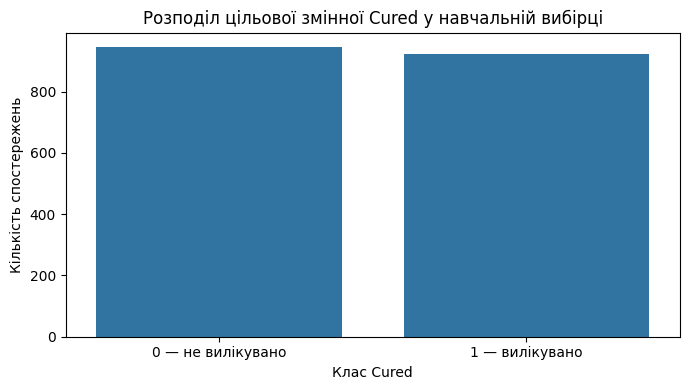

In [9]:
# Візуалізація балансу класів
plt.figure(figsize=(7, 4))
sns.countplot(x=y_train)
plt.title("Розподіл цільової змінної Cured у навчальній вибірці")
plt.xlabel("Клас Cured")
plt.ylabel("Кількість спостережень")
plt.xticks([0, 1], ["0 — не вилікувано", "1 — вилікувано"])
plt.tight_layout()
plt.show()

**Висновок:**  
Баланс класів оцінюється за кількістю та часткою спостережень кожного значення `Cured` у навчальній вибірці. Якщо частки близькі, класи можна вважати відносно збалансованими; значна перевага одного класу свідчить про дисбаланс. За дисбалансу Accuracy може бути оманливою, тому додатково важливо аналізувати precision, recall і F1-score.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

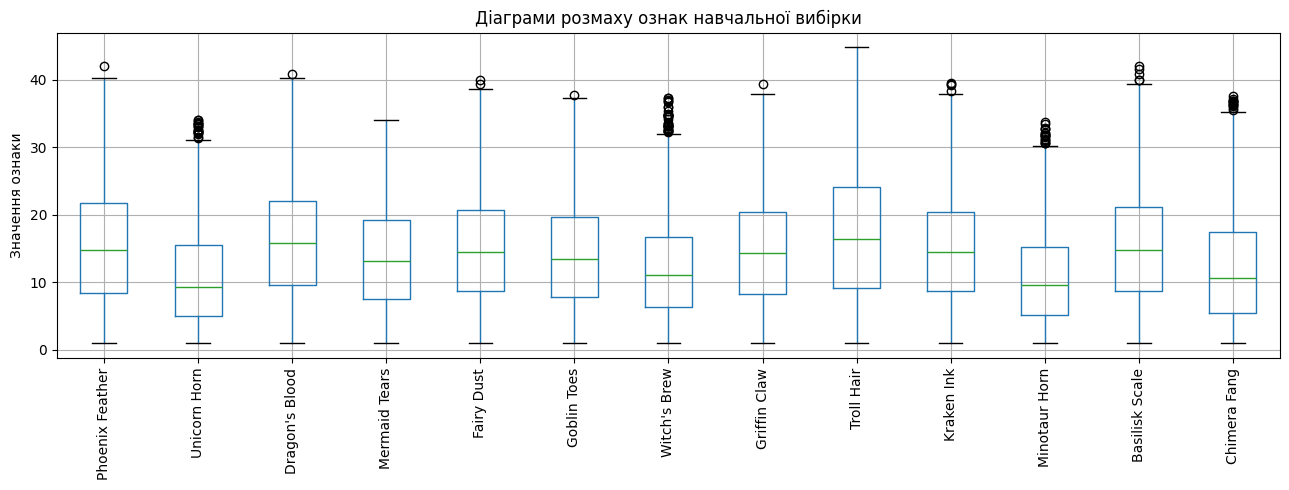

In [10]:
# Діаграми розмаху для ознак навчальної вибірки
plt.figure(figsize=(13, 5))
X_train.boxplot(rot=90)
plt.title("Діаграми розмаху ознак навчальної вибірки")
plt.ylabel("Значення ознаки")
plt.tight_layout()
plt.show()

In [11]:
# Кількість потенційних викидів за правилом 1,5 IQR
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_counts = ((X_train.lt(lower_bound)) | (X_train.gt(upper_bound))).sum()
outlier_counts = outlier_counts.sort_values(ascending=False)

display(outlier_counts.rename("Кількість потенційних викидів").to_frame())
print("Загальна кількість потенційних викидів за всіма ознаками:", int(outlier_counts.sum()))

,Кількість потенційних викидів
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


Загальна кількість потенційних викидів за всіма ознаками: 99


**Висновок про викиди:**  
Потенційні викиди визначено окремо для кожної ознаки за межами `Q1 − 1,5·IQR` та `Q3 + 1,5·IQR`. Найбільшу їх кількість показують верхні рядки таблиці результатів. Такі спостереження не слід автоматично видаляти: вони можуть бути коректними рідкісними значеннями, а їх вилучення здатне призвести до втрати важливої інформації та зміни розподілу даних.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

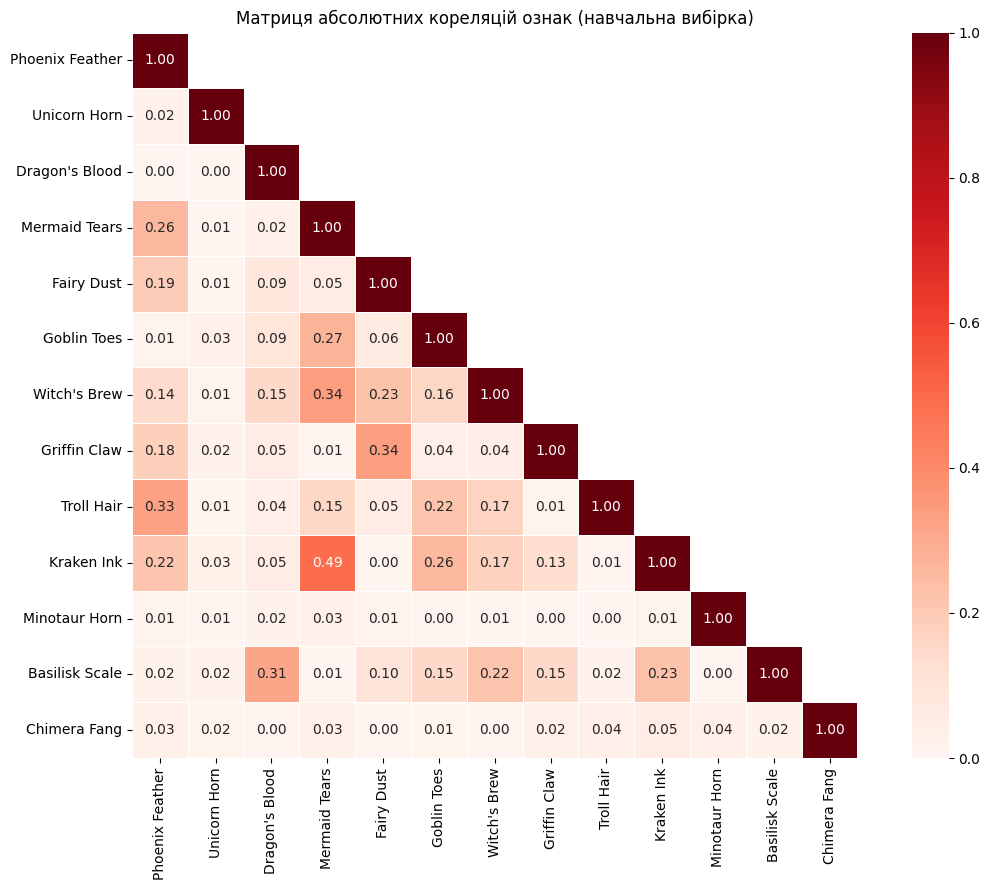

In [12]:
# Кореляційна матриця ознак на навчальній вибірці
mtx = X_train.corr().abs()
mask = np.triu(np.ones_like(mtx, dtype=bool), k=1)

plt.figure(figsize=(12, 9))
sns.heatmap(
    mtx,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="Reds",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5
)
plt.title("Матриця абсолютних кореляцій ознак (навчальна вибірка)")
plt.tight_layout()
plt.show()

In [13]:
# Кореляція ознак із цільовою змінною Cured — лише навчальна вибірка
train_corr = pd.concat([X_train, y_train.rename("Cured")], axis=1).corr()
target_corr = train_corr["Cured"].drop("Cured").sort_values(
    key=lambda values: values.abs(), ascending=False
)
display(target_corr.rename("Кореляція з Cured").to_frame())
print("\\nНайсильніший лінійний зв'язок за модулем має ознака:", target_corr.abs().idxmax())

,Кореляція з Cured
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


\nНайсильніший лінійний зв'язок за модулем має ознака: Troll Hair


**Висновок про кореляції:**  
У тепловій карті найбільш тісні пари ознак визначаються за найбільшими значеннями поза діагоналлю. Зв’язок окремих ознак із `Cured` оцінюється за таблицею кореляцій, відсортованою за абсолютною величиною коефіцієнта. Кореляція показує лінійний зв’язок, але сама по собі не доводить причинно-наслідкову залежність.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [14]:
# Стандартизація: параметри обчислюються тільки на X_train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Розмір стандартизованої навчальної вибірки:", X_train_scaled.shape)
print("Розмір стандартизованої тестової вибірки:", X_test_scaled.shape)
print("Середні значення ознак після стандартизації (train):")
print(np.round(X_train_scaled.mean(axis=0), 4))

Розмір стандартизованої навчальної вибірки: (1870, 13)
Розмір стандартизованої тестової вибірки: (468, 13)
Середні значення ознак після стандартизації (train):
[ 0.  0.  0. -0. -0.  0.  0. -0.  0.  0.  0.  0. -0.]


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [15]:
# Навчання базової логістичної регресії та оцінювання на тестовій вибірці
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)

baseline_accuracy = accuracy_score(y_test, y_pred)
baseline_f1 = f1_score(y_test, y_pred, zero_division=0)

print(f"Accuracy базової логістичної регресії: {baseline_accuracy:.4f}")
print(f"F1-score базової логістичної регресії: {baseline_f1:.4f}")
print("\\nЗвіт класифікації:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy базової логістичної регресії: 0.8932
F1-score базової логістичної регресії: 0.8941
\nЗвіт класифікації:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

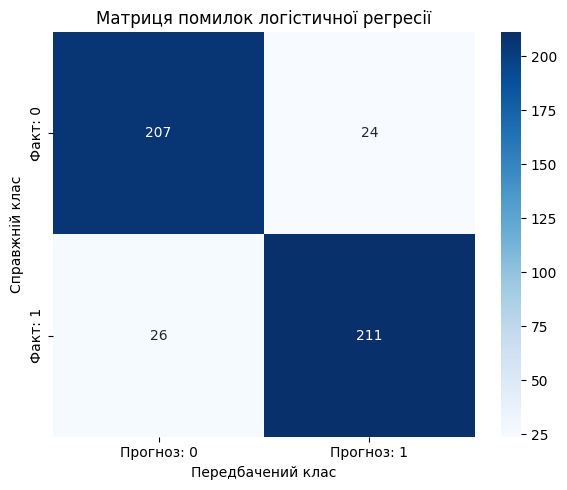

Правильно визначено клас 0 (TN): 207
Помилково визначено клас 1 (FP): 24
Помилково визначено клас 0 (FN): 26
Правильно визначено клас 1 (TP): 211


In [16]:
# Матриця помилок і теплова карта
conf = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    conf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Прогноз: 0", "Прогноз: 1"],
    yticklabels=["Факт: 0", "Факт: 1"]
)
plt.title("Матриця помилок логістичної регресії")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = conf.ravel()
print(f"Правильно визначено клас 0 (TN): {tn}")
print(f"Помилково визначено клас 1 (FP): {fp}")
print(f"Помилково визначено клас 0 (FN): {fn}")
print(f"Правильно визначено клас 1 (TP): {tp}")

In [17]:
# Порівняння справжніх і передбачених класів для 10 випадкових тестових спостережень
predictions_df = pd.DataFrame({
    "Справжній клас": y_test,
    "Передбачений клас": y_pred
})
predictions_df["Результат"] = np.where(
    predictions_df["Справжній клас"] == predictions_df["Передбачений клас"],
    "Правильно",
    "Помилка"
)
display(predictions_df.sample(min(10, len(predictions_df)), random_state=42))

,Справжній клас,Передбачений клас,Результат
1133,0,1,Помилка
1018,0,0,Правильно
1761,1,0,Помилка
564,1,1,Правильно
1467,1,1,Правильно
1927,0,0,Правильно
408,1,1,Правильно
2094,1,1,Правильно
532,0,0,Правильно
291,1,1,Правильно


**Висновок щодо якості логістичної регресії:**  
Матриця помилок дає змогу окремо побачити хибнопозитивні (FP) і хибнонегативні (FN) прогнози; їх кількість наведена під тепловою картою. Однієї Accuracy недостатньо, особливо за дисбалансу класів, оскільки вона не показує співвідношення precision і recall для кожного класу. Тому оцінювання доповнено classification report та F1-score.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [18]:
# Простори параметрів для GridSearchCV і RandomizedSearchCV
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear", "lbfgs"],
    "max_iter": [500, 1000, 2000]
}

param_dist = {
    "C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100],
    "solver": ["liblinear", "lbfgs"],
    "max_iter": [500, 1000, 1500, 2000, 3000]
}

print("Параметри для повного перебору:", param_grid)
print("\\nПараметри для випадкового пошуку:", param_dist)

Параметри для повного перебору: {'C': [0.01, 0.1, 1, 10, 100], 'solver': ['liblinear', 'lbfgs'], 'max_iter': [500, 1000, 2000]}
\nПараметри для випадкового пошуку: {'C': [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100], 'solver': ['liblinear', 'lbfgs'], 'max_iter': [500, 1000, 1500, 2000, 3000]}


In [19]:
# Повний перебір комбінацій гіперпараметрів
grid = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)
grid.fit(X_train_scaled, y_train)

print("Найкращі параметри GridSearchCV:", grid.best_params_)
print(f"Найкраща середня Accuracy на крос-валідації: {grid.best_score_:.4f}")

Найкращі параметри GridSearchCV: {'C': 10, 'max_iter': 500, 'solver': 'liblinear'}
Найкраща середня Accuracy на крос-валідації: 0.8674


In [20]:
# Випадковий пошук гіперпараметрів
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри RandomizedSearchCV:", random_search.best_params_)
print(f"Найкраща середня Accuracy на крос-валідації: {random_search.best_score_:.4f}")

Найкращі параметри RandomizedSearchCV: {'solver': 'liblinear', 'max_iter': 500, 'C': 30}
Найкраща середня Accuracy на крос-валідації: 0.8674


In [21]:
# Оцінювання найкращої моделі з двох методів пошуку на тестовій вибірці
best_search = grid if grid.best_score_ >= random_search.best_score_ else random_search
best_model = best_search.best_estimator_
best_search_pred = best_model.predict(X_test_scaled)

best_search_accuracy = accuracy_score(y_test, best_search_pred)
best_search_f1 = f1_score(y_test, best_search_pred, zero_division=0)

print("Обраний метод пошуку:", "GridSearchCV" if best_search is grid else "RandomizedSearchCV")
print("Найкращі параметри:", best_search.best_params_)
print(f"Accuracy після підбору: {best_search_accuracy:.4f}")
print(f"F1-score після підбору: {best_search_f1:.4f}")
print("\\nЗвіт класифікації:")
print(classification_report(y_test, best_search_pred, zero_division=0))

Обраний метод пошуку: GridSearchCV
Найкращі параметри: {'C': 10, 'max_iter': 500, 'solver': 'liblinear'}
Accuracy після підбору: 0.8932
F1-score після підбору: 0.8941
\nЗвіт класифікації:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
Порівняйте `best_score_` двох методів на крос-валідації та тестові значення Accuracy і F1-score з базовою логістичною регресією. Обраною є модель із вищою середньою Accuracy на крос-валідації. Підбір вважається корисним, якщо тестові метрики також зросли; якщо вони не змінилися або знизилися, покращення якості не підтверджено.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [22]:
# Порівняння логістичної регресії, SVC та дерева рішень на однаковій тестовій вибірці
models = {
    "Логістична регресія (базова)": model,
    "SVC": SVC(),
    "Дерево рішень": DecisionTreeClassifier(random_state=42)
}

comparison_rows = []
comparison_predictions = {}

for model_name, current_model in models.items():
    if model_name != "Логістична регресія (базова)":
        current_model.fit(X_train_scaled, y_train)
    current_pred = current_model.predict(X_test_scaled)
    comparison_predictions[model_name] = current_pred
    comparison_rows.append({
        "Модель": model_name,
        "Accuracy": accuracy_score(y_test, current_pred),
        "F1-score": f1_score(y_test, current_pred, zero_division=0)
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("Модель").sort_values(
    by=["F1-score", "Accuracy"], ascending=False
)
display(comparison_df.style.format({"Accuracy": "{:.4f}", "F1-score": "{:.4f}"}))

best_model_name = comparison_df.index[0]
print("Найкраща модель за F1-score (за рівності — за Accuracy):", best_model_name)
print("Її показники:")
print(comparison_df.loc[best_model_name])

,Accuracy,F1-score
Модель,,
SVC,0.9594,0.9600
Логістична регресія (базова),0.8932,0.8941
Дерево рішень,0.8654,0.8657


Найкраща модель за F1-score (за рівності — за Accuracy): SVC
Її показники:
Accuracy    0.959402
F1-score    0.960000
Name: SVC, dtype: float64


### 13. Висновки до лабораторної роботи

**Ваші висновки:**

1. Під час первинного аналізу було перевірено розмір, типи даних, пропуски, дублікати та описову статистику. Конкретні значення наведені у відповідних таблицях вище.
2. Аналіз викидів за правилом 1,5 IQR і кореляцій виконано лише на навчальній вибірці, щоб не використовувати інформацію з тестових даних під час дослідження та підготовки моделі. Найбільш виражені викиди й кореляційні зв’язки визначаються за отриманими таблицями та графіками.
3. Базова логістична регресія отримала Accuracy **{baseline_accuracy:.4f}** і F1-score **{baseline_f1:.4f}** на тестовій вибірці.
4. Після підбору гіперпараметрів обрано **{"GridSearchCV" if best_search is grid else "RandomizedSearchCV"}** з параметрами **{best_search.best_params_}**. На тестовій вибірці Accuracy становить **{best_search_accuracy:.4f}**, F1-score — **{best_search_f1:.4f}**. Порівняння з базовою моделлю наведено за цими метриками.
5. За результатами порівняння трьох алгоритмів найкращою за F1-score (за рівності — за Accuracy) стала модель **{best_model_name}**. Її Accuracy дорівнює **{comparison_df.loc[best_model_name, "Accuracy"]:.4f}**, а F1-score — **{comparison_df.loc[best_model_name, "F1-score"]:.4f}**.

Таким чином, у роботі виконано первинний аналіз даних, поділ на навчальну й тестову вибірки, стандартизацію ознак, побудову та оцінювання логістичної регресії, підбір її гіперпараметрів і порівняння з SVC та деревом рішень.